# Historical LOS: Linear vs Ridge vs Histogram Gradient Boosting

Compare three regressors on the existing 2,976 profiles, without COMORBIDITY_INDEX,
MONITORING_HOURS or CARE_TEAM_SIZE. This is a new follow-up comparison, not evidence
that it preceded earlier CAPSTONE experiments. Better performance is not assumed.

All models use the same ten source predictors and the same engineered features
as the saved Ridge. All use the same imputation, scaling and one-hot encoding,
fitted on TRAIN only. Existing TRAIN/VALIDATION/TEST assignments are preserved.
Fixed candidates: no hyperparameter search. Select by validation MAE, then evaluate
the test partition. The test set has been used previously: this is NOT a fresh
independent validation. Profile-level splitting is not a verified patient-level split.

Run cells top to bottom. Required: numpy, pandas, scipy, scikit-learn, openpyxl,
matplotlib, joblib and threadpoolctl. Nothing modifies the SAS dashboard or source data.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits
import joblib

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'Model/los_ridge_export/los_features.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the project root or Model folder.')
sys.path.insert(0, str(ROOT / 'Model/los_ridge_export'))
from los_features import prepare, FEATURES, NUMERIC, CATEGORICAL, NUMERIC_FE, DIAGNOSIS_FE
SEED = 42
print('Project:', ROOT)
print('scikit-learn:', sklearn.__version__)


Project: /Users/jmj3047/Library/CloudStorage/GoogleDrive-kathy.minjee.jang@gmail.com/내 드라이브/2026/하반기/UC/11522_Technology Capstone Research Project PG
scikit-learn: 1.5.2


## 1. Load data and preserve the existing partitions

In [2]:
source = ROOT / 'EDA/READMIT_FE.xlsx'
split_path = ROOT / 'Model/los_ridge_export/split_assignments.csv'
source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
reference = json.loads((ROOT / 'Model/los_ridge_export/model_manifest.json').read_text())
assert source_hash == reference['source_sha256'], 'Source changed; review before comparing.'
df = pd.read_excel(source, sheet_name='READMIT_LOS')
splits = pd.read_csv(split_path)
assert df.TEMPLATE_ID.is_unique and splits.TEMPLATE_ID.is_unique
assert set(df.TEMPLATE_ID) == set(splits.TEMPLATE_ID)
df = df.merge(splits, on='TEMPLATE_ID', validate='one_to_one')
assert len(df) == 2976
X = df[FEATURES].copy()
y = pd.to_numeric(df['TOTAL_LOS'], errors='raise')
assert y.notna().all() and np.isfinite(y).all() and (y >= 0).all()
assert not set(['COMORBIDITY_INDEX','MONITORING_HOURS','CARE_TEAM_SIZE']) & set(FEATURES)
masks = {name: df.PARTITION.eq(name) for name in ['TRAIN','VALIDATION','TEST']}
assert [int(masks[s].sum()) for s in masks] == [2380, 298, 298]
display(df.groupby('PARTITION').size().rename('Rows').to_frame())
print('Source predictors:', FEATURES)
print('Derived predictors:', NUMERIC_FE + DIAGNOSIS_FE)


,Rows
PARTITION,
TEST,298
TRAIN,2380
VALIDATION,298


Source predictors: ['PATIENT_AGE', 'NUM_CHRONIC_COND', 'NUM_VISITS', 'DOCTOR', 'DEPARTMENT', 'GENDER', 'Patient location', 'RACE_CD', 'ICD9_TARGET', 'DIAGNOSIS_ICD_CODE']
Derived predictors: ['LOG1P_VISITS', 'AGE_CENTRED_SQUARED', 'AGE_X_CHRONIC', 'ICD_FAMILY', 'CHRONIC_COUNT_BAND']


## 2. Fixed models and common preprocessing

HistGB uses absolute-error loss (aligned with MAE); Linear and Ridge fit squared
error. Thus this compares specified modelling configurations, not algorithms with
identical training objectives. One-hot encoding is used for all three for a
controlled first comparison; it is not a claim of optimal HistGB configuration.
HistGB early stopping is disabled so it does not silently create a different split.


In [3]:
def make_pipeline(estimator):
    preprocessing = ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('scale', StandardScaler())]), NUMERIC + NUMERIC_FE),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         CATEGORICAL + DIAGNOSIS_FE)
    ], sparse_threshold=0.0)
    return Pipeline([('features', FunctionTransformer(prepare, validate=False)),
                     ('preprocess', preprocessing), ('model', estimator)])

models = {
    'Linear Regression': make_pipeline(LinearRegression()),
    'Ridge Regression': make_pipeline(Ridge(alpha=1)),
    'HistGB Regressor': make_pipeline(HistGradientBoostingRegressor(
        loss='absolute_error', max_iter=180, learning_rate=0.05,
        max_leaf_nodes=7, min_samples_leaf=20, l2_regularization=5,
        early_stopping=False, categorical_features=None, random_state=SEED))
}
def metrics(actual, predicted):
    return {'MAE_days': float(mean_absolute_error(actual, predicted)),
            'RMSE_days': float(np.sqrt(mean_squared_error(actual, predicted))),
            'R2': float(r2_score(actual, predicted)),
            'Negative_predictions': int((predicted < 0).sum())}


## 3. Fit on TRAIN; choose using VALIDATION only

In [4]:
validation_rows = []
with threadpool_limits(limits=1):
    for name, model in models.items():
        model.fit(X.loc[masks['TRAIN']], y.loc[masks['TRAIN']])
        prediction = model.predict(X.loc[masks['VALIDATION']])
        assert np.isfinite(prediction).all()
        validation_rows.append({'Model': name, **metrics(y.loc[masks['VALIDATION']], prediction)})
validation = pd.DataFrame(validation_rows).sort_values('MAE_days')
selected = validation.iloc[0]['Model']
display(validation)
print('Selected before evaluating TEST:', selected)
OUT = ROOT / 'Model/los_historical_three_models_outputs' / datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True, exist_ok=False)
(OUT / 'selection_before_test.json').write_text(json.dumps(
    {'selected_model': selected, 'criterion': 'Validation MAE',
     'validation': validation.to_dict('records')}, indent=2))


,Model,MAE_days,RMSE_days,R2,Negative_predictions
2,HistGB Regressor,4.974513e+00,8.321093e+00,-4.118047e-02,0
1,Ridge Regression,5.065881e+00,7.641973e+00,1.218346e-01,1
0,Linear Regression,2.750465e+08,4.027416e+09,-2.439036e+17,5


Selected before evaluating TEST: HistGB Regressor


669

## 4. Test comparison (previously used holdout)

No rounding or clipping of predictions before evaluation. A TRAIN-median baseline
is included to check whether a learned model adds value. Do not reselect the model
or tune parameters using the test results below.


In [5]:
test_rows = []
predictions = df.loc[masks['TEST'], ['TEMPLATE_ID']].copy()
predictions['Actual_LOS_days'] = y.loc[masks['TEST']]
with threadpool_limits(limits=1):
    for name, model in models.items():
        pred = model.predict(X.loc[masks['TEST']])
        assert np.isfinite(pred).all()
        predictions[name] = pred
        test_rows.append({'Model': name, **metrics(y.loc[masks['TEST']], pred)})
median_pred = np.full(int(masks['TEST'].sum()), y.loc[masks['TRAIN']].median())
test_rows.append({'Model': 'Train median baseline', **metrics(y.loc[masks['TEST']], median_pred)})
test = pd.DataFrame(test_rows)
comparison = test.merge(validation[['Model','MAE_days']].rename(columns={'MAE_days':'Validation_MAE_days'}), on='Model', how='left')
comparison['Selected_on_validation'] = comparison.Model.eq(selected)
display(comparison)
ridge_mae = float(test.loc[test.Model.eq('Ridge Regression'), 'MAE_days'].iloc[0])
hgb_mae = float(test.loc[test.Model.eq('HistGB Regressor'), 'MAE_days'].iloc[0])
print(f'HistGB test MAE reduction vs Ridge: {(ridge_mae-hgb_mae)/ridge_mae*100:.2f}% (negative means worse)')
print('Previously saved Ridge test MAE:', reference['metrics']['test']['MAE'])
print('Current Ridge test MAE:', ridge_mae)


,Model,MAE_days,RMSE_days,R2,Negative_predictions,Validation_MAE_days,Selected_on_validation
0,Linear Regression,1.263099e+09,1.141955e+10,-1.364890e+18,3,2.750465e+08,False
1,Ridge Regression,5.568254e+00,8.739358e+00,2.006106e-01,0,5.065881e+00,False
2,HistGB Regressor,5.757207e+00,1.008409e+01,-6.432030e-02,0,4.974513e+00,True
3,Train median baseline,5.993289e+00,1.007855e+01,-6.315227e-02,0,NaN,False


HistGB test MAE reduction vs Ridge: -3.39% (negative means worse)
Previously saved Ridge test MAE: 5.5682539876395065
Current Ridge test MAE: 5.568253987639509


## 5. Plot and save the evidence

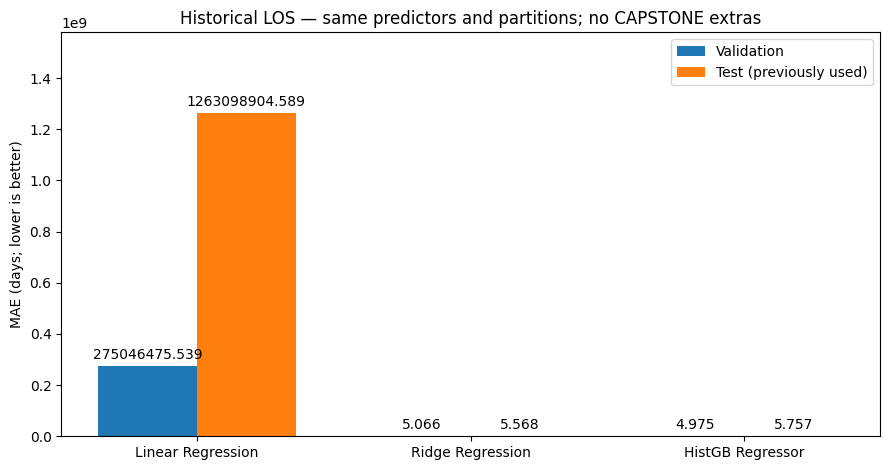

Saved to: /Users/jmj3047/Library/CloudStorage/GoogleDrive-kathy.minjee.jang@gmail.com/내 드라이브/2026/하반기/UC/11522_Technology Capstone Research Project PG/Model/los_historical_three_models_outputs/20261021_004722_584105


In [6]:
fig, ax = plt.subplots(figsize=(9, 4.8))
names = list(models)
positions = np.arange(len(names))
val_values = validation.set_index('Model').loc[names, 'MAE_days']
test_values = test.set_index('Model').loc[names, 'MAE_days']
ax.bar(positions-0.18, val_values, width=0.36, label='Validation')
ax.bar(positions+0.18, test_values, width=0.36, label='Test (previously used)')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)
ax.set_xticks(positions, names)
ax.set_ylabel('MAE (days; lower is better)')
ax.set_title('Historical LOS — same predictors and partitions; no CAPSTONE extras')
ax.set_ylim(0, max(val_values.max(), test_values.max()) * 1.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'mae_comparison.png', dpi=180)
plt.show()
comparison.to_csv(OUT / 'model_comparison.csv', index=False)
predictions.to_csv(OUT / 'test_predictions.csv', index=False)
for name, model in models.items():
    joblib.dump(model, OUT / (name.lower().replace(' ', '_') + '.joblib'))
manifest = {'source': str(source.relative_to(ROOT)), 'source_sha256': source_hash,
    'split_sha256': hashlib.sha256(split_path.read_bytes()).hexdigest(),
    'features': FEATURES, 'derived_features': NUMERIC_FE + DIAGNOSIS_FE,
    'excluded_extras': ['COMORBIDITY_INDEX','MONITORING_HOURS','CARE_TEAM_SIZE'],
    'rows': {s: int(m.sum()) for s,m in masks.items()}, 'selected_model': selected,
    'parameters': {name: model.named_steps['model'].get_params() for name,model in models.items()},
    'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__},
    'limitations': ['Previously used test partition', 'Synthetic/profile data',
                    'Not an admission-time clinical validation', 'Fixed configurations; no search'],
    'model_loading': 'Keep Model/los_ridge_export on sys.path for los_features.prepare.'}
(OUT / 'manifest.json').write_text(json.dumps(manifest, indent=2))
print('Saved to:', OUT)


## Interpretation and next step

- Compare validation MAE first, and report test MAE without selecting a new winner on test.
- A negative MAE reduction means HistGB was worse; report it rather than omitting it.
- This comparison does not prove performance on CAPSTONE or the value of its extra columns.
- CAPSTONE feature effects require paired experiments on the same CAPSTONE partitions.
- Additional feature availability and independence from LOS must be checked before claiming
  admission-time benefit. Do not claim that this follow-up preceded experiments already run.
